# Analyse exploratoire du maillage des points de recharge

**Problématique.** Dans le cadre de la transition énergétique, où se situent les déserts de recharge en France et les territoires sous-équipés en bornes de 150 kW et plus, et quelle dynamique de déploiement permet d'orienter les futures installations ?

**Données.** Les deux jeux propres produits par `01_eda_cleaning.ipynb` :
- `irve_points_clean.csv` : 166 430 points de charge (une ligne par point), France métropolitaine et 5 départements d'outre-mer ;
- `communes_population_clean.csv` : 34 868 communes, y compris celles sans borne, avec leur population et la distance de leur centre au point de charge le plus proche.

**Définitions** (validées lors du nettoyage) :
- *désert de recharge* : commune sans aucun point sur son territoire et dont le centre est à plus de 10 km du point le plus proche ;
- *désert 150 kW* : commune sans point de 150 kW ou plus et à plus de 30 km d'un tel point ; le seuil de 30 km découle du règlement (UE) 2023/1804 (AFIR), qui impose un parc de recharge comprenant un point d'au moins 150 kW tous les 60 km sur le réseau routier central européen.

**Plan.** Axe 1 : couverture du territoire et déserts. Axe 2 : puissance. Axe 3 : acteurs et implantation. Puis corrélations, tendances et synthèse.

Les corrélations sont mesurées avec le coefficient de Spearman : population et nombre de points sont très asymétriques (beaucoup de petites communes, quelques très grandes villes) et le coefficient de Pearson serait dominé par ces valeurs extrêmes.

In [1]:
# Système et fichiers
import json
import re
import unicodedata
import warnings
from pathlib import Path

# Manipulation et statistiques
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, spearmanr

# Visualisation et cartographie
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from shapely.geometry import shape

warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
milliers = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " "))


In [2]:
CHEMIN_POINTS = Path("../data/processed/irve_points_clean.csv")
CHEMIN_COMMUNES = Path("../data/processed/communes_population_clean.csv")
CHEMIN_REFERENTIEL = Path("../data/raw/referentiel_communes.csv")
DEPARTEMENTS_OUTRE_MER = ["971", "972", "973", "974", "976"]

points = pd.read_csv(CHEMIN_POINTS, dtype={"code_insee": str, "code_departement": str},
                     parse_dates=["date_mise_en_service"])
communes = pd.read_csv(CHEMIN_COMMUNES, dtype={"code_insee": str, "code_departement": str})

# Contours des départements métropolitains (fusion des communes du référentiel 2025)
referentiel = pd.read_csv(CHEMIN_REFERENTIEL, sep=";", dtype=str,
                          usecols=["com_code", "dep_code", "dep_name", "geo_shape"])
referentiel = referentiel.loc[referentiel["dep_code"].str.len() == 2]
contours_communes = gpd.GeoDataFrame(
    referentiel[["dep_code", "dep_name"]],
    geometry=referentiel["geo_shape"].map(lambda s: shape(json.loads(s))), crs=4326)
departements_geo = contours_communes.dissolve(by="dep_code", as_index=False).to_crs(2154)
departements_geo["geometry"] = departements_geo.geometry.simplify(200)

# Indicateurs par département
departements = communes.groupby(["code_departement", "region"], as_index=False).agg(
    population=("population", "sum"), communes=("code_insee", "size"),
    nb_pdc=("nb_pdc", "sum"), nb_pdc_150kw=("nb_pdc_150kw", "sum"),
    deserts=("desert_recharge", "sum"), deserts_150kw=("desert_150kw", "sum"))
departements["habitants_desert"] = departements["code_departement"].map(
    communes.loc[communes["desert_recharge"]].groupby("code_departement")["population"].sum()).fillna(0)
departements["pdc_pour_10000_hab"] = departements["nb_pdc"] * 10000 / departements["population"]
departements["part_150kw_%"] = departements["nb_pdc_150kw"] / departements["nb_pdc"].where(
    departements["nb_pdc"] > 0) * 100
departements = departements.merge(
    referentiel[["dep_code", "dep_name"]].drop_duplicates().rename(
        columns={"dep_code": "code_departement", "dep_name": "nom_departement"}),
    on="code_departement", how="left")
departements.loc[departements["code_departement"] == "971", "nom_departement"] = "Guadeloupe"
departements.loc[departements["code_departement"] == "972", "nom_departement"] = "Martinique"
departements.loc[departements["code_departement"] == "973", "nom_departement"] = "Guyane"
departements.loc[departements["code_departement"] == "974", "nom_departement"] = "La Réunion"
departements.loc[departements["code_departement"] == "976", "nom_departement"] = "Mayotte"

print(f"Points de charge : {len(points):,} | Stations : {points['id_station'].nunique():,}")
print(f"Communes : {len(communes):,} | Habitants : {communes['population'].sum():,}")
print(f"Départements : {len(departements)} (dont {departements['code_departement'].isin(DEPARTEMENTS_OUTRE_MER).sum()} d'outre-mer)")


Points de charge : 166,430 | Stations : 49,180
Communes : 34,868 | Habitants : 68,258,311
Départements : 101 (dont 5 d'outre-mer)


## Axe 1 : couverture du territoire et déserts de recharge

Communes sans aucun point : 24,038 (68.9 %), 12,006,663 habitants (17.6 %)
Distance du centre de la commune au point le plus proche : médiane 3.24 km, 90e centile 7.00 km
Pondérée par la population : médiane 0.64 km
Désert à  5 km : 9,087 communes, 3,802,474 habitants (5.57 %)
Désert à 10 km :   685 communes,   614,653 habitants (0.90 %)
Désert à 15 km :    68 communes,   414,991 habitants (0.61 %)


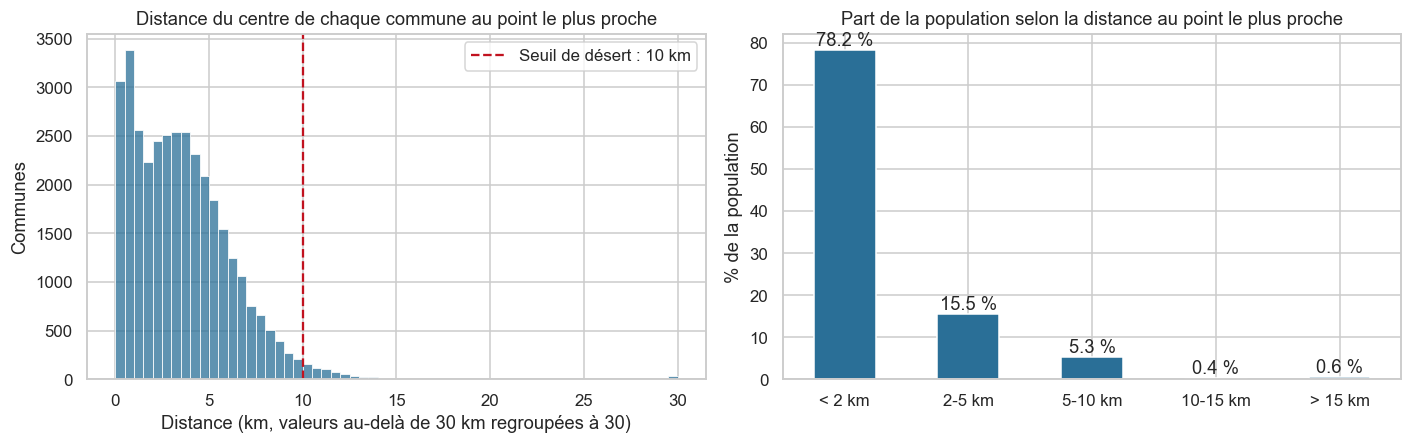

In [3]:
habitants = communes["population"].sum()
sans_point = communes["nb_pdc"] == 0
print(f"Communes sans aucun point : {sans_point.sum():,} ({sans_point.mean() * 100:.1f} %), "
      f"{communes.loc[sans_point, 'population'].sum():,} habitants "
      f"({communes.loc[sans_point, 'population'].sum() / habitants * 100:.1f} %)")
print(f"Distance du centre de la commune au point le plus proche : médiane "
      f"{communes['distance_pdc_km'].median():.2f} km, 90e centile "
      f"{communes['distance_pdc_km'].quantile(0.9):.2f} km")
print(f"Pondérée par la population : médiane "
      f"{np.repeat(communes['distance_pdc_km'], communes['population'] // 100).median():.2f} km")
for seuil in [5, 10, 15]:
  desert = (communes["distance_pdc_km"] > seuil) & sans_point
  print(f"Désert à {seuil:>2} km : {desert.sum():>5,} communes, "
        f"{communes.loc[desert, 'population'].sum():>9,} habitants "
        f"({communes.loc[desert, 'population'].sum() / habitants * 100:.2f} %)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(communes["distance_pdc_km"].clip(upper=30), bins=60, ax=axes[0], color="#2a6f97")
axes[0].axvline(10, color="#c1121f", linestyle="--", label="Seuil de désert : 10 km")
axes[0].set(title="Distance du centre de chaque commune au point le plus proche",
            xlabel="Distance (km, valeurs au-delà de 30 km regroupées à 30)", ylabel="Communes")
axes[0].legend()
classes = pd.cut(communes["distance_pdc_km"], [0, 2, 5, 10, 15, np.inf],
                 labels=["< 2 km", "2-5 km", "5-10 km", "10-15 km", "> 15 km"], right=False)
part = communes.groupby(classes, observed=False)["population"].sum() / habitants * 100
part.plot.bar(ax=axes[1], color="#2a6f97")
axes[1].set(title="Part de la population selon la distance au point le plus proche",
            xlabel="", ylabel="% de la population")
axes[1].tick_params(axis="x", rotation=0)
for i, v in enumerate(part):
  axes[1].text(i, v + 1, f"{v:.1f} %", ha="center")
plt.tight_layout()
plt.show()


**Lecture.**
- 24 038 communes (68,9 %) n'ont aucun point de charge, mais elles ne regroupent que 17,6 % de la population : les communes sans borne sont surtout de petites communes.
- La distance médiane entre le centre d'une commune et le point le plus proche est de 3,2 km ; pondérée par la population, elle tombe à 0,6 km. La moitié des Français vit à moins de 640 mètres (à vol d'oiseau) d'un point de charge.
- Au seuil de 10 km, 685 communes sont des déserts de recharge : 614 653 habitants, soit 0,90 % de la population. Le résultat est sensible au seuil : 5,57 % de la population à 5 km, 0,61 % à 15 km.

**Limite.** La distance part du centre géométrique de la commune et se mesure à vol d'oiseau : elle sous-estime le trajet réel par la route.

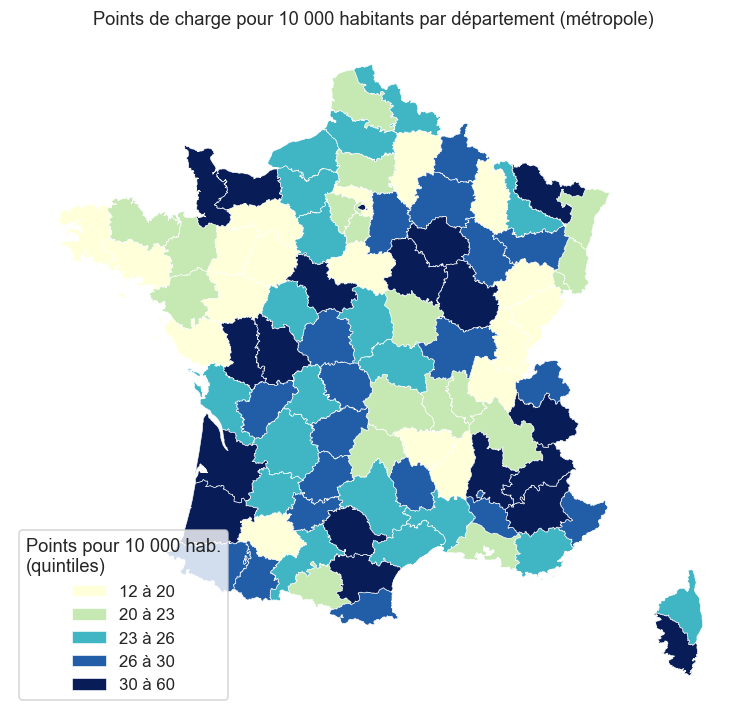

Départements les moins équipés (points pour 10 000 habitants)
code_departement   nom_departement  population  nb_pdc  pdc_pour_10000_hab
             976           Mayotte      256518       0                 0.0
             973            Guyane      290446       3                 0.1
             972        Martinique      361738      39                 1.1
             971        Guadeloupe      381752     165                 4.3
             974        La Réunion      888663     440                 5.0
              93 Seine-Saint-Denis     1689629    2006                11.9
              61              Orne      275888     337                12.2
              70       Haute-Saône      233565     305                13.1
              43       Haute-Loire      228202     365                16.0
              39              Jura      258078     415                16.1

Départements les plus équipés
code_departement nom_departement  population  nb_pdc  pdc_pour_10000_hab
         

In [4]:
metropole = departements_geo.merge(departements, left_on="dep_code", right_on="code_departement")
bornes_quintiles = metropole["pdc_pour_10000_hab"].quantile([0, 0.2, 0.4, 0.6, 0.8, 1]).to_numpy()
metropole["classe_equipement"] = pd.cut(
    metropole["pdc_pour_10000_hab"], bornes_quintiles, include_lowest=True,
    labels=[f"{a:.0f} à {b:.0f}" for a, b in zip(bornes_quintiles[:-1], bornes_quintiles[1:])])
fig, ax = plt.subplots(figsize=(8.5, 8.5))
metropole.plot(column="classe_equipement", cmap="YlGnBu", categorical=True, legend=True,
               edgecolor="white", linewidth=0.4, ax=ax,
               legend_kwds={"title": "Points pour 10 000 hab.\n(quintiles)", "loc": "lower left"})
ax.set_title("Points de charge pour 10 000 habitants par département (métropole)")
ax.set_axis_off()
plt.show()

print("Départements les moins équipés (points pour 10 000 habitants)")
print(departements.nsmallest(10, "pdc_pour_10000_hab")[
    ["code_departement", "nom_departement", "population", "nb_pdc", "pdc_pour_10000_hab"]
].round(1).to_string(index=False))
print("\nDépartements les plus équipés")
print(departements.nlargest(5, "pdc_pour_10000_hab")[
    ["code_departement", "nom_departement", "population", "nb_pdc", "pdc_pour_10000_hab"]
].round(1).to_string(index=False))
moyenne_nationale = departements["nb_pdc"].sum() * 10000 / departements["population"].sum()
print(f"\nMoyenne nationale : {moyenne_nationale:.1f} points pour 10 000 habitants | "
      f"médiane des départements : {departements['pdc_pour_10000_hab'].median():.1f}")


**Lecture.**
- La France compte en moyenne 24,4 points pour 10 000 habitants (médiane des départements : 23,9).
- Les cinq départements d'outre-mer sont les moins équipés : Mayotte n'a aucun point publié, la Guyane 3 points, la Martinique 1,1 point pour 10 000 habitants.
- En métropole, la Seine-Saint-Denis (11,9) est le département le moins équipé rapporté à sa population, devant l'Orne (12,2) et la Haute-Saône (13,1). La Vienne arrive en tête (60,2), devant les Hautes-Alpes (42,8) et la Savoie (42,3).
- L'équipement par habitant ne suit donc ni l'opposition ville/campagne, ni la taille des départements : il dépend aussi de politiques locales de déploiement (syndicats d'énergie départementaux, stations de montagne).

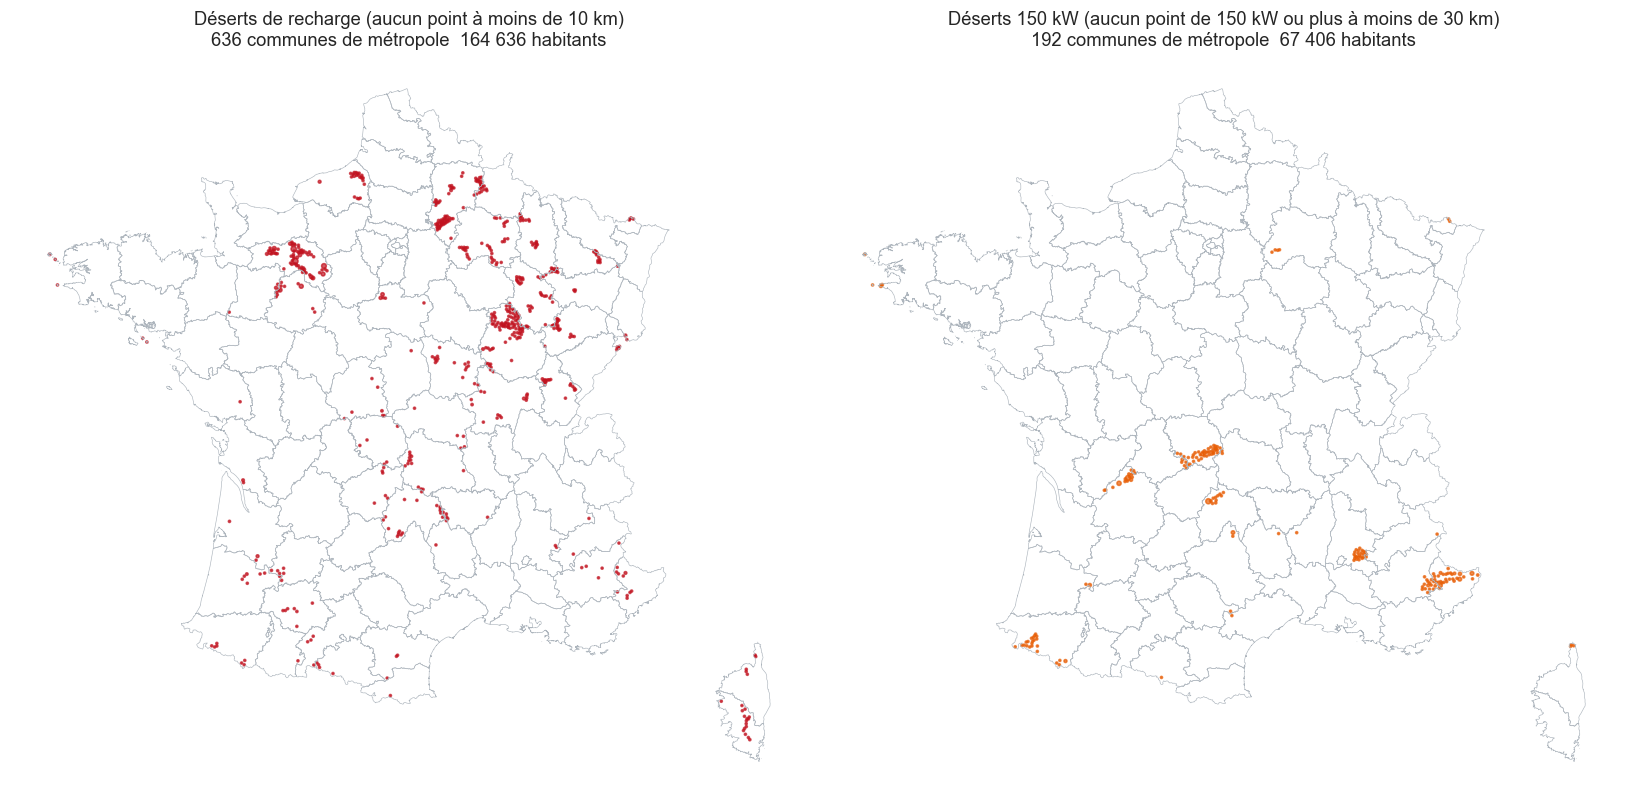

In [5]:
centres = gpd.GeoDataFrame(communes, geometry=gpd.points_from_xy(communes["longitude"], communes["latitude"]),
                           crs=4326).to_crs(2154)
centres_metropole = centres.loc[~centres["code_departement"].isin(DEPARTEMENTS_OUTRE_MER)]
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
for ax, colonne, couleur, titre in [
    (axes[0], "desert_recharge", "#c1121f", "Déserts de recharge (aucun point à moins de 10 km)"),
    (axes[1], "desert_150kw", "#e85d04", "Déserts 150 kW (aucun point de 150 kW ou plus à moins de 30 km)")]:
  departements_geo.boundary.plot(ax=ax, color="#adb5bd", linewidth=0.4)
  selection = centres_metropole.loc[centres_metropole[colonne]]
  selection.plot(ax=ax, color=couleur, markersize=np.clip(selection["population"] / 300, 2, 60), alpha=0.7)
  ax.set_title(f"{titre}\n{len(selection):,} communes de métropole, "
               f"{selection['population'].sum():,} habitants".replace(",", " "))
  ax.set_axis_off()
plt.tight_layout()
plt.show()


**Lecture.**
- En métropole, les déserts de recharge (636 communes, 164 636 habitants) forment des poches rurales dans la moitié nord du pays : Côte-d'Or (91 communes), Orne (71), Aisne (68), Haute-Marne (36), Marne (35). Aucune commune d'Île-de-France n'est concernée.
- Les déserts 150 kW de métropole (192 communes, 67 406 habitants) se situent surtout en zone de montagne ou rurale isolée : Creuse (41 communes), Alpes-Maritimes (30), Pyrénées-Atlantiques et Drôme (23 chacune), Alpes-de-Haute-Provence (17).
- Chaque point représente le centre d'une commune ; sa taille est proportionnelle à la population.

                            communes  deserts_10km  habitants_desert_10km  deserts_150kw  habitants_desert_150kw  part_population_desert_150kw_%
region                                                                                                                                          
Mayotte                           17            17                 256518             17                  256518                           100.0
Guyane                            22            18                 137431             22                  290446                           100.0
Normandie                       2644            93                  46391              0                       0                             0.0
Martinique                        34            10                  40102             34                  361738                           100.0
Bourgogne-Franche-Comté         3685           165                  28393              0                       0                  

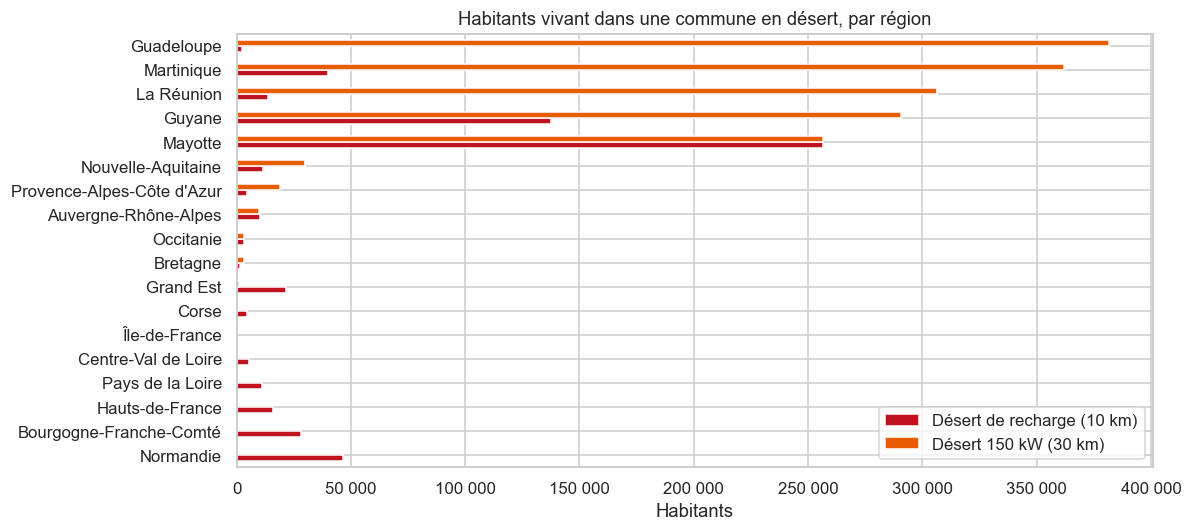

In [6]:
par_region = communes.groupby("region").apply(lambda g: pd.Series({
    "communes": len(g),
    "deserts_10km": int(g["desert_recharge"].sum()),
    "habitants_desert_10km": int(g.loc[g["desert_recharge"], "population"].sum()),
    "deserts_150kw": int(g["desert_150kw"].sum()),
    "habitants_desert_150kw": int(g.loc[g["desert_150kw"], "population"].sum()),
    "part_population_desert_150kw_%": g.loc[g["desert_150kw"], "population"].sum() / g["population"].sum() * 100,
}), include_groups=False).sort_values("habitants_desert_10km", ascending=False)
par_region = par_region.astype({c: int for c in par_region.columns if not c.endswith("%")})
print(par_region.round(1).to_string())

fig, ax = plt.subplots(figsize=(11, 5))
par_region[["habitants_desert_10km", "habitants_desert_150kw"]].sort_values(
    "habitants_desert_150kw").plot.barh(ax=ax, color=["#c1121f", "#e85d04"])
ax.xaxis.set_major_formatter(milliers)
ax.set(title="Habitants vivant dans une commune en désert, par région", xlabel="Habitants", ylabel="")
ax.legend(["Désert de recharge (10 km)", "Désert 150 kW (30 km)"])
plt.tight_layout()
plt.show()


**Lecture.**
- En nombre d'habitants, les déserts sont d'abord ultramarins : toute la population de Mayotte (256 518 habitants, aucun point publié) et 47 % de celle de la Guyane (137 431 habitants) vivent en désert de recharge.
- Pour la recharge de 150 kW et plus, toute la population de Mayotte, de la Guyane, de la Martinique et de la Guadeloupe est en désert, et 34,5 % de celle de La Réunion.
- En métropole, la part de la population en désert 150 kW ne dépasse 0,5 % dans aucune région.

**Limite.** Les départements d'outre-mer sont des îles ou un territoire peu relié par la route : la distance au point le plus proche y est parfois mesurée vers une autre île. Leur cas relève d'un diagnostic distinct.

Corrélation de Spearman population / nombre de points : toutes communes 0.63 (p = 0.0e+00) ; communes équipées 0.59 (p = 0.0e+00)
               communes  part_equipees_pct  population  nb_pdc  pdc_pour_10000_hab
population                                                                        
< 500             18269                8.2     4099823    6338                15.5
500-2 000         11107               40.3    10955979   23092                21.1
2 000-10 000       4445               86.3    18353735   50938                27.8
10 000-50 000       913               97.2    18342515   45878                25.0
> 50 000            134               98.5    16506259   40178                24.3


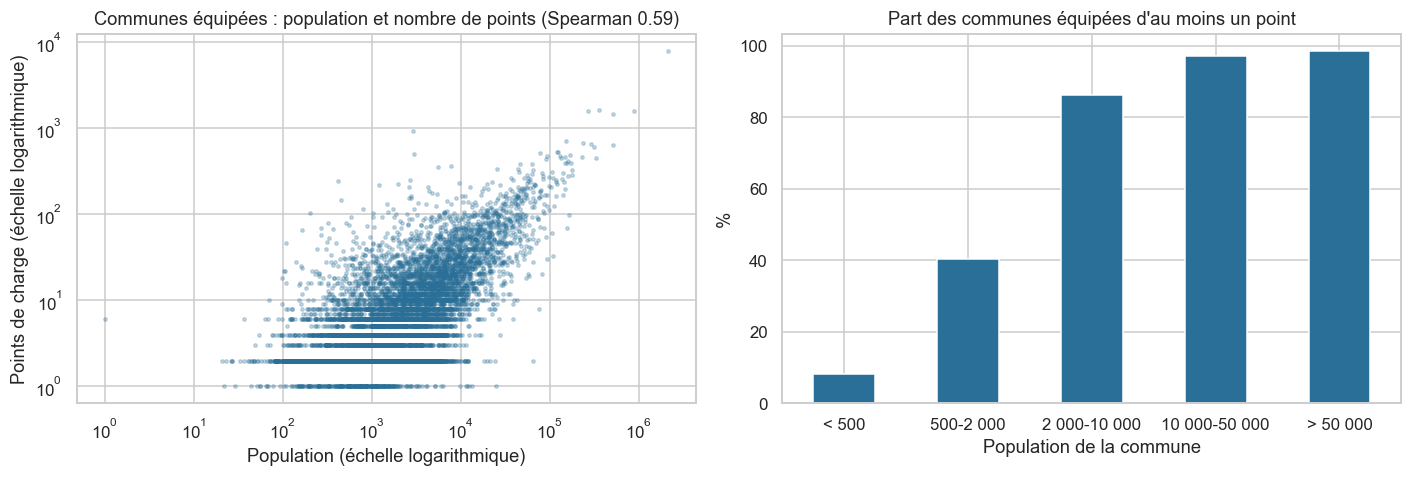

In [7]:
equipees = communes.loc[communes["nb_pdc"] > 0]
rho, p = spearmanr(communes["population"], communes["nb_pdc"])
rho_eq, p_eq = spearmanr(equipees["population"], equipees["nb_pdc"])
print(f"Corrélation de Spearman population / nombre de points : toutes communes {rho:.2f} "
      f"(p = {p:.1e}) ; communes équipées {rho_eq:.2f} (p = {p_eq:.1e})")
tranches = pd.cut(communes["population"], [0, 500, 2000, 10000, 50000, np.inf],
                  labels=["< 500", "500-2 000", "2 000-10 000", "10 000-50 000", "> 50 000"], right=False)
par_tranche = communes.groupby(tranches, observed=False).agg(
    communes=("code_insee", "size"), part_equipees_pct=("nb_pdc", lambda s: (s > 0).mean() * 100),
    population=("population", "sum"), nb_pdc=("nb_pdc", "sum"))
par_tranche["pdc_pour_10000_hab"] = par_tranche["nb_pdc"] * 10000 / par_tranche["population"]
print(par_tranche.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(equipees["population"], equipees["nb_pdc"], s=5, alpha=0.25, color="#2a6f97")
axes[0].set(xscale="log", yscale="log", xlabel="Population (échelle logarithmique)",
            ylabel="Points de charge (échelle logarithmique)",
            title=f"Communes équipées : population et nombre de points (Spearman {rho_eq:.2f})")
par_tranche["part_equipees_pct"].plot.bar(ax=axes[1], color="#2a6f97")
axes[1].set(title="Part des communes équipées d'au moins un point", xlabel="Population de la commune",
            ylabel="%")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


**Lecture.**
- La corrélation de Spearman entre population et nombre de points est forte (0,63 sur toutes les communes, 0,59 sur les communes équipées) : plus une commune est peuplée, plus elle a de points, sans surprise.
- Le seuil d'équipement est net : 8,2 % des communes de moins de 500 habitants ont au moins un point, contre 40,3 % entre 500 et 2 000 habitants et 86,3 % entre 2 000 et 10 000.
- Rapporté à la population, l'équipement est le plus élevé dans les communes de 2 000 à 10 000 habitants (27,8 points pour 10 000 habitants) et le plus faible dans les communes de moins de 500 habitants (15,5).

**Limite.** Une corrélation ne dit rien de la cause : les grandes communes concentrent aussi les commerces, les parkings et les axes de passage.

## Axe 2 : puissance

Les catégories sont celles de l'annexe III du règlement (UE) 2023/1804 (AFIR) :

| Courant | Catégorie | Puissance |
|---|---|---|
| Alternatif (AC) | Lent | < 7,4 kW |
| Alternatif (AC) | Moyen | 7,4 à 22 kW |
| Alternatif (AC) | Rapide | > 22 kW |
| Continu (DC) | Lent | < 50 kW |
| Continu (DC) | Rapide | 50 à 150 kW |
| Continu (DC) | Ultra-rapide niveau 1 | 150 à 350 kW |
| Continu (DC) | Ultra-rapide niveau 2 | ≥ 350 kW |

**Règles de classement.** Un point est en courant continu s'il dispose d'une prise combo CCS ou CHAdeMO, ou si sa puissance dépasse 43 kW (au-delà de la puissance maximale de la recharge en courant alternatif). La valeur 22,08 kW (3 × 32 A × 230 V) est la puissance nominale d'une borne de 22 kW et reste classée en AC moyen.

                                       points  part_%
classe_afir                                          
AC lent (< 7,4 kW)                      17777    10.7
AC moyen (7,4-22 kW)                    93006    55.9
AC rapide (> 22 kW)                      2782     1.7
DC lent (< 50 kW)                        6211     3.7
DC rapide (50-150 kW)                   15736     9.5
DC ultra-rapide niveau 1 (150-350 kW)   27318    16.4
DC ultra-rapide niveau 2 (≥ 350 kW)      3600     2.2

Courant continu : 31.8 % des points | prise CCS ou CHAdeMO : 29.5 % | puissance > 43 kW sans prise continue : 3,795
Points à exactement 22 kW : 37.4 % | 22,08 kW : 8.9 %
Seuil 150 kW : ≥ 150 kW 18.6 % ; > 150 kW 13.8 % ; exactement 150 kW 7,964 points


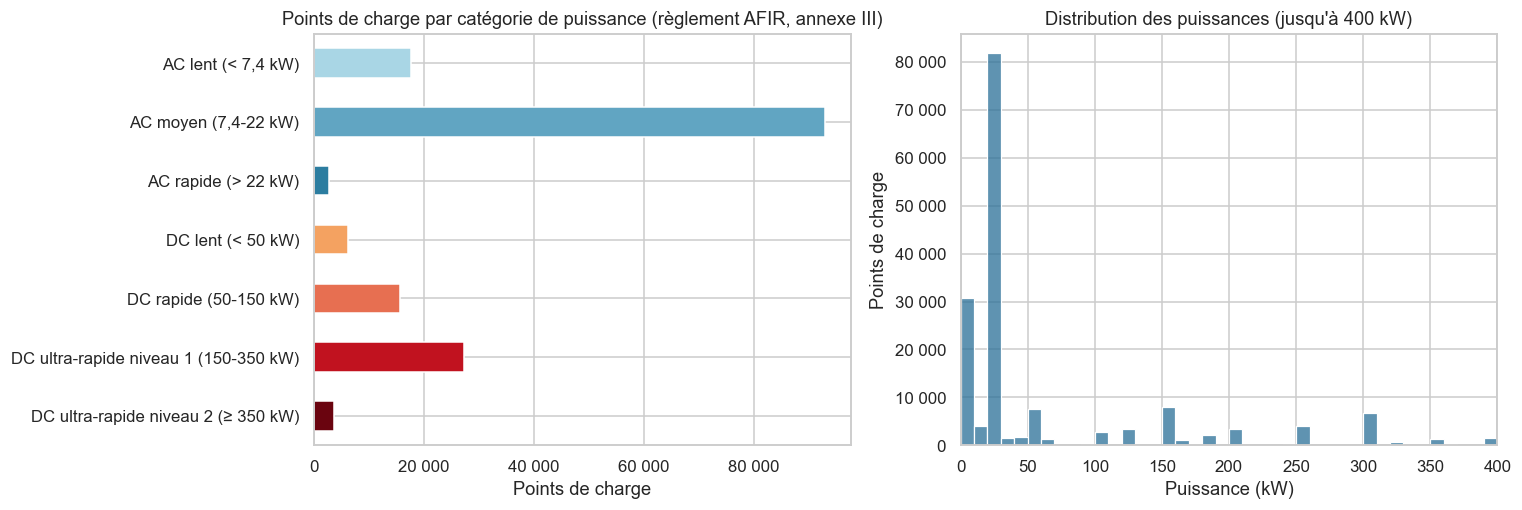

In [8]:
# Courant continu : prise combo CCS ou CHAdeMO, ou puissance supérieure à 43 kW (au-delà de la
# puissance maximale de la recharge en courant alternatif)
continu = (points["prise_type_combo_ccs"] | points["prise_type_chademo"] | (points["puissance_kw"] > 43))
points["courant"] = np.where(continu, "Continu (DC)", "Alternatif (AC)")
# 22,08 kW = 3 × 32 A × 230 V : valeur nominale d'une borne de 22 kW, classée en AC moyen
puissance = points["puissance_kw"]
classe_ac = np.select([puissance < 7.4, puissance <= 22.08],
                      ["AC lent (< 7,4 kW)", "AC moyen (7,4-22 kW)"], "AC rapide (> 22 kW)")
classe_dc = pd.cut(puissance, [-np.inf, 50, 150, 350, np.inf], right=False,
                   labels=["DC lent (< 50 kW)", "DC rapide (50-150 kW)",
                           "DC ultra-rapide niveau 1 (150-350 kW)", "DC ultra-rapide niveau 2 (≥ 350 kW)"]).astype(str)
points["classe_afir"] = np.where(continu, classe_dc, classe_ac)
ordre = ["AC lent (< 7,4 kW)", "AC moyen (7,4-22 kW)", "AC rapide (> 22 kW)", "DC lent (< 50 kW)",
         "DC rapide (50-150 kW)", "DC ultra-rapide niveau 1 (150-350 kW)", "DC ultra-rapide niveau 2 (≥ 350 kW)"]
repartition = points["classe_afir"].value_counts().reindex(ordre).fillna(0).astype(int)
print(pd.DataFrame({"points": repartition, "part_%": (repartition / len(points) * 100).round(1)}).to_string())
print(f"\nCourant continu : {continu.mean() * 100:.1f} % des points | "
      f"prise CCS ou CHAdeMO : {(points['prise_type_combo_ccs'] | points['prise_type_chademo']).mean() * 100:.1f} % | "
      f"puissance > 43 kW sans prise continue : {((points['puissance_kw'] > 43) & ~(points['prise_type_combo_ccs'] | points['prise_type_chademo'])).sum():,}")
print(f"Points à exactement 22 kW : {(points['puissance_kw'] == 22).mean() * 100:.1f} % | "
      f"22,08 kW : {(points['puissance_kw'] == 22.08).mean() * 100:.1f} %")
print(f"Seuil 150 kW : ≥ 150 kW {(points['puissance_kw'] >= 150).mean() * 100:.1f} % ; "
      f"> 150 kW {(points['puissance_kw'] > 150).mean() * 100:.1f} % ; "
      f"exactement 150 kW {(points['puissance_kw'] == 150).sum():,} points")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
couleurs = ["#a9d6e5", "#61a5c2", "#2c7da0", "#f4a261", "#e76f51", "#c1121f", "#6a040f"]
repartition.plot.barh(ax=axes[0], color=couleurs)
axes[0].invert_yaxis()
axes[0].xaxis.set_major_formatter(milliers)
axes[0].set(title="Points de charge par catégorie de puissance (règlement AFIR, annexe III)",
            xlabel="Points de charge", ylabel="")
sns.histplot(points["puissance_kw"], bins=np.arange(0, 410, 10), ax=axes[1], color="#2a6f97")
axes[1].set(title="Distribution des puissances (jusqu'à 400 kW)", xlabel="Puissance (kW)",
            ylabel="Points de charge", xlim=(0, 400))
axes[1].yaxis.set_major_formatter(milliers)
plt.tight_layout()
plt.show()


**Lecture.**
- La recharge en courant alternatif de 7,4 à 22 kW domine : 55,9 % des points. Les deux valeurs 22 kW (37,4 %) et 22,08 kW (8,9 %) forment à elles seules près de la moitié du parc.
- 31,8 % des points sont en courant continu ; 18,6 % sont ultra-rapides (150 kW et plus), dont 2,2 % à 350 kW et plus.
- **Sensibilité du seuil de 150 kW** : 7 964 points sont à exactement 150 kW. Avec un seuil strict (plus de 150 kW), la part ultra-rapide passerait de 18,6 % à 13,8 %. Le seuil « 150 kW et plus » suit la définition AFIR.

**Limite.** La puissance est déclarée par le producteur de données : c'est une puissance nominale, pas la puissance réellement délivrée au véhicule. 2 526 puissances absentes ont été complétées par la médiane des points ayant les mêmes prises.

                            points  points_150kw  part_150kw_%
region                                                        
Guadeloupe                     165             0           0.0
Guyane                           3             0           0.0
Martinique                      39             0           0.0
La Réunion                     440            11           2.5
Île-de-France                28928          3619          12.5
Corse                         1000           142          14.2
Provence-Alpes-Côte d'Azur   13724          2084          15.2
Nouvelle-Aquitaine           20000          3368          16.8
Normandie                     9371          1606          17.1
Occitanie                    16486          3338          20.2
Hauts-de-France              13550          2749          20.3
Bretagne                      6898          1420          20.6
Pays de la Loire              7754          1607          20.7
Grand Est                    14993          3225       

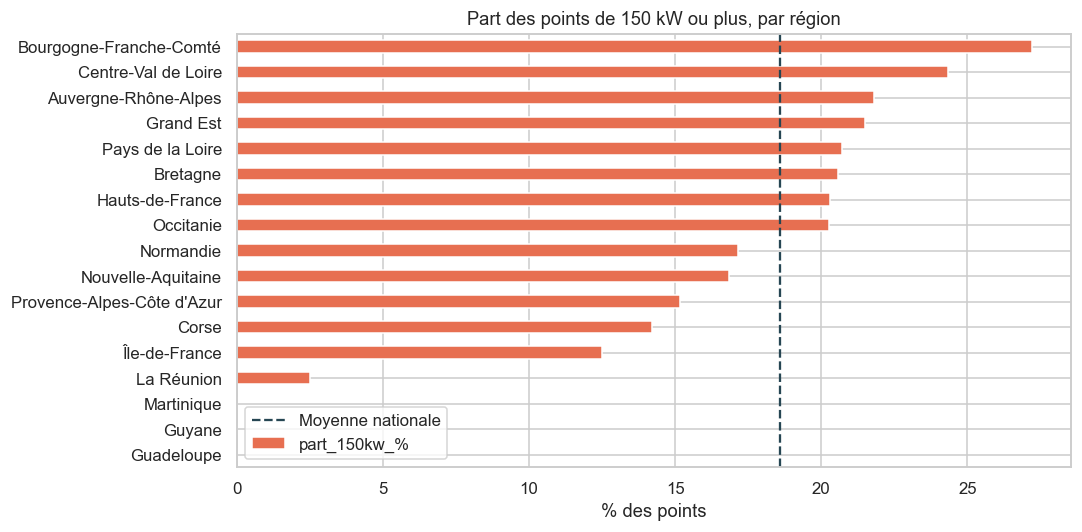

In [9]:
region_150 = points.groupby("region").agg(points=("id_pdc", "size"),
                                          points_150kw=("puissance_kw", lambda s: (s >= 150).sum()))
region_150["part_150kw_%"] = region_150["points_150kw"] / region_150["points"] * 100
region_150 = region_150.sort_values("part_150kw_%")
print(region_150.round(1).to_string())
print(f"\nDistance du centre de la commune au point de 150 kW ou plus le plus proche : médiane "
      f"{communes['distance_150kw_km'].median():.1f} km (métropole "
      f"{communes.loc[~communes['code_departement'].isin(DEPARTEMENTS_OUTRE_MER), 'distance_150kw_km'].median():.1f} km)")

fig, ax = plt.subplots(figsize=(10, 5))
region_150["part_150kw_%"].plot.barh(ax=ax, color="#e76f51")
ax.axvline(points["puissance_kw"].ge(150).mean() * 100, color="#264653", linestyle="--",
           label="Moyenne nationale")
ax.set(title="Part des points de 150 kW ou plus, par région", xlabel="% des points", ylabel="")
ax.legend()
plt.tight_layout()
plt.show()


**Lecture.**
- La part des points de 150 kW et plus varie du simple au double en métropole : 12,5 % en Île-de-France, 27,2 % en Bourgogne-Franche-Comté.
- Les régions traversées par de grands axes de transit (Bourgogne-Franche-Comté, Centre-Val de Loire) ont la plus forte part de recharge ultra-rapide ; l'Île-de-France, très équipée en recharge lente sur voirie, a la plus faible.
- Outre-mer, aucun point de 150 kW n'est publié en Guadeloupe, en Martinique ni en Guyane, et 11 points le sont à La Réunion (2,5 %).
- La distance médiane du centre d'une commune au point de 150 kW ou plus le plus proche est de 7,8 km.

**Limite.** Sans données de trafic ni de réseau routier, le lien avec les axes de transit est une interprétation, pas une mesure.

In [10]:
zone = np.where(communes["code_departement"].isin(DEPARTEMENTS_OUTRE_MER), "Outre-mer", "Métropole")
comparaison = communes.groupby(zone).apply(lambda g: pd.Series({
    "habitants": g["population"].sum(),
    "points_150kw": g["nb_pdc_150kw"].sum(),
    "points_150kw_pour_100000_hab": g["nb_pdc_150kw"].sum() * 100000 / g["population"].sum(),
    "habitants_desert_150kw": g.loc[g["desert_150kw"], "population"].sum(),
    "part_population_desert_150kw_%": g.loc[g["desert_150kw"], "population"].sum() / g["population"].sum() * 100,
    "distance_150kw_mediane_ponderee_km": g.loc[g.index.repeat(g["population"] // 100), "distance_150kw_km"].median(),
}), include_groups=False)
print(comparaison.T.round(2).to_string())


                                      Métropole   Outre-mer
habitants                           66079194.00  2179117.00
points_150kw                           30907.00       11.00
points_150kw_pour_100000_hab              46.77        0.50
habitants_desert_150kw                 67406.00  1596937.00
part_population_desert_150kw_%             0.10       73.28
distance_150kw_mediane_ponderee_km         2.14     1411.38


**Lecture : métropole et outre-mer.**

Un point de 150 kW délivre jusqu'à 50 kWh en 20 minutes, contre 22 kWh en une heure pour un point de 22 kW (maximums théoriques : la puissance réellement acceptée dépend du véhicule et diminue quand la batterie se remplit). C'est la recharge des arrêts courts lors des longs trajets.

- En métropole, 99,9 % de la population a un point de 150 kW ou plus à moins de 30 km : 46,8 points pour 100 000 habitants, distance médiane pondérée par la population de 2,1 km. Les 67 406 habitants en désert 150 kW vivent dans des communes rurales isolées ou de montagne.
- Outre-mer, 11 points de 150 kW sont publiés, tous à La Réunion (0,5 pour 100 000 habitants) ; 73,3 % de la population est en désert 150 kW.
- La distance médiane de 1 411 km outre-mer n'a pas de sens concret : en Guadeloupe, en Martinique, en Guyane et à Mayotte, aucun point de 150 kW n'est publié, et le plus proche se trouve sur un autre territoire.

**Limite.** Ne pas être en désert signifie qu'un point existe à moins de 30 km, pas que l'offre suffit : IRVE décrit l'offre, ni l'attente aux bornes, ni la demande.

## Axe 3 : acteurs et implantation

Opérateurs distincts : 377 libellés, 338 après regroupement des variantes d'écriture
Part des 5 premiers opérateurs : 33.2 % | des 15 premiers : 59.9 %
Indice de concentration HHI par département : médiane 1033 ; départements au-dessus de 2 500 (marché très concentré) : 9
code_departement nom_departement  nb_pdc    hhi
             971      Guadeloupe     165 7137.0
             974      La Réunion     440 6770.0
             973          Guyane       3 5556.0
              81            Tarn    1452 5342.0
              79     Deux-Sèvres    1383 4612.0
             972      Martinique      39 4030.0
              48          Lozère     210 2996.0
              75           Paris    7972 2805.0


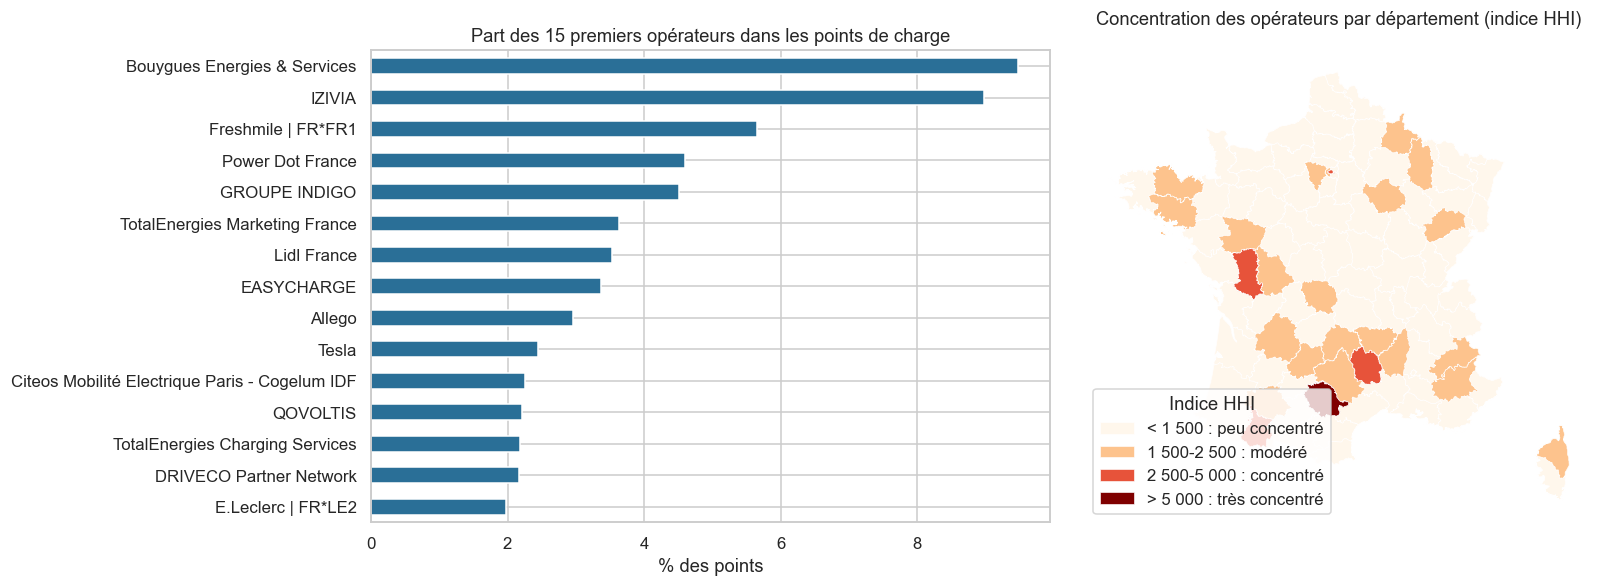

In [11]:
def cle_acteur(nom):
  nom = unicodedata.normalize("NFKD", str(nom)).encode("ascii", "ignore").decode().upper()
  return re.sub(r"[^A-Z0-9]", "", nom)


points["operateur_cle"] = points["nom_operateur"].map(cle_acteur)
libelle = points.groupby("operateur_cle")["nom_operateur"].agg(lambda s: s.value_counts().index[0])
top = points["operateur_cle"].value_counts()
print(f"Opérateurs distincts : {points['nom_operateur'].nunique():,} libellés, "
      f"{points['operateur_cle'].nunique():,} après regroupement des variantes d'écriture")
part_top = top.head(15) / len(points) * 100
print(f"Part des 5 premiers opérateurs : {part_top.head(5).sum():.1f} % | des 15 premiers : {part_top.sum():.1f} %")


def indice_hhi(groupe):
  parts = groupe.value_counts(normalize=True) * 100
  return (parts ** 2).sum()


hhi = points.groupby("code_departement")["operateur_cle"].apply(indice_hhi).rename("hhi")
departements = departements.merge(hhi, left_on="code_departement", right_index=True, how="left")
print(f"Indice de concentration HHI par département : médiane {hhi.median():.0f} ; "
      f"départements au-dessus de 2 500 (marché très concentré) : {(hhi > 2500).sum()}")
print(departements.nlargest(8, "hhi")[["code_departement", "nom_departement", "nb_pdc", "hhi"]]
      .round(0).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
part_top.rename(libelle).sort_values().plot.barh(ax=axes[0], color="#2a6f97")
axes[0].set(title="Part des 15 premiers opérateurs dans les points de charge", xlabel="% des points",
            ylabel="")
carte_hhi = departements_geo.merge(departements, left_on="dep_code", right_on="code_departement")
carte_hhi["classe_hhi"] = pd.cut(carte_hhi["hhi"], [0, 1500, 2500, 5000, 10000],
                                 labels=["< 1 500 : peu concentré", "1 500-2 500 : modéré",
                                         "2 500-5 000 : concentré", "> 5 000 : très concentré"])
carte_hhi.plot(column="classe_hhi", cmap="OrRd", categorical=True, legend=True, ax=axes[1],
               edgecolor="white", linewidth=0.4,
               legend_kwds={"title": "Indice HHI", "loc": "lower left"})
axes[1].set_title("Concentration des opérateurs par département (indice HHI)")
axes[1].set_axis_off()
plt.tight_layout()
plt.show()


**Lecture.**
- 338 opérateurs exploitent le réseau, une fois regroupées les variantes d'écriture d'un même nom (377 libellés bruts). Le marché est fragmenté au niveau national : les 5 premiers opérateurs exploitent 33,2 % des points, les 15 premiers 59,9 %.
- L'indice de Herfindahl-Hirschman (HHI, somme des carrés des parts de marché, de 0 à 10 000) mesure la concentration dans chaque département. Sa médiane est de 1 033 (peu concentré), mais 9 départements dépassent 2 500 (très concentré) : Guadeloupe (7 137), La Réunion (6 770), Guyane (5 556), Tarn (5 342), Deux-Sèvres (4 612), Martinique (4 030), Lozère (2 996), Paris (2 805).
- Dans ces départements, un acteur exploite la moitié du parc ou plus : réseau public d'un syndicat d'énergie (Guadeloupe 84 %, Tarn 50 %, Lozère 52 %), distributeur local d'électricité (Seolis, Deux-Sèvres 52 %) ou opérateur privé (Freshmile outre-mer, TotalEnergies à Paris 43 %). Pour 7 de ces 8 acteurs dominants, la puissance médiane de leurs points est de 22 kW ou moins.

**Limite.** Les variantes d'écriture ont été regroupées en ignorant majuscules, accents et ponctuation ; des filiales d'un même groupe restent comptées séparément.

courant                               Alternatif (AC)  Continu (DC)  points
implantation_station                                                       
Parking privé réservé à la clientèle             92.4           7.6    1993
Parking privé à usage public                     67.6          32.4   42898
Parking public                                   69.4          30.6   43091
Station dédiée à la recharge rapide              25.4          74.6   15815
Voirie                                           78.0          22.0   62633

Khi-deux = 16,721, p = 0.0e+00 ; V de Cramér = 0.32

Puissance médiane par implantation (kW) : {'Parking privé réservé à la clientèle': 22.0, 'Parking privé à usage public': 22.0, 'Parking public': 22.0, 'Station dédiée à la recharge rapide': 180.0, 'Voirie': 22.0}


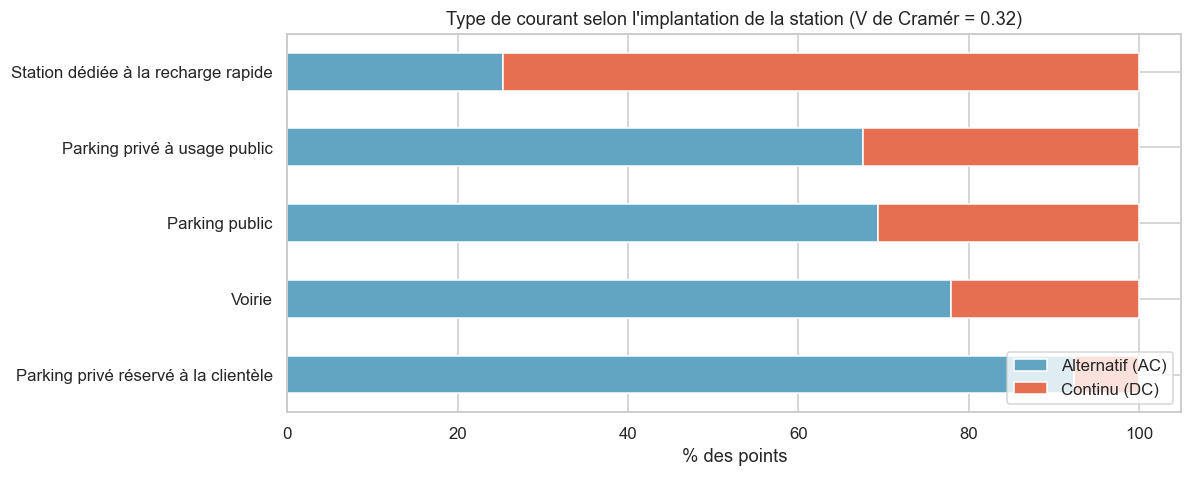

In [12]:
tableau = pd.crosstab(points["implantation_station"], points["courant"])
chi2, p_chi2, _, _ = chi2_contingency(tableau)
v_cramer = np.sqrt(chi2 / (tableau.to_numpy().sum() * (min(tableau.shape) - 1)))
print(pd.crosstab(points["implantation_station"], points["courant"], normalize="index").mul(100).round(1)
      .assign(points=tableau.sum(axis=1)).to_string())
print(f"\nKhi-deux = {chi2:,.0f}, p = {p_chi2:.1e} ; V de Cramér = {v_cramer:.2f}")
mediane_implantation = points.groupby("implantation_station")["puissance_kw"].median()
print("\nPuissance médiane par implantation (kW) :", mediane_implantation.round(1).to_dict())

fig, ax = plt.subplots(figsize=(11, 4.5))
(pd.crosstab(points["implantation_station"], points["courant"], normalize="index") * 100).sort_values(
    "Continu (DC)").plot.barh(stacked=True, ax=ax, color=["#61a5c2", "#e76f51"])
ax.set(title=f"Type de courant selon l'implantation de la station (V de Cramér = {v_cramer:.2f})",
       xlabel="% des points", ylabel="")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


**Lecture.**
- Le type d'implantation est modérément associé au type de courant (V de Cramér = 0,32 ; le test du khi-deux est significatif, mais sur 166 430 points tout écart l'est).
- Les stations dédiées à la recharge rapide sont à 74,6 % en courant continu (puissance médiane 180 kW) ; la voirie (22,0 %) et les parkings réservés à la clientèle (7,6 %) sont surtout équipés en courant alternatif (puissance médiane 22 kW).

**Limite.** L'implantation diverge entre producteurs pour 41,2 % des points publiés plusieurs fois : c'est la variable la moins fiable du jeu de données.

## Corrélations

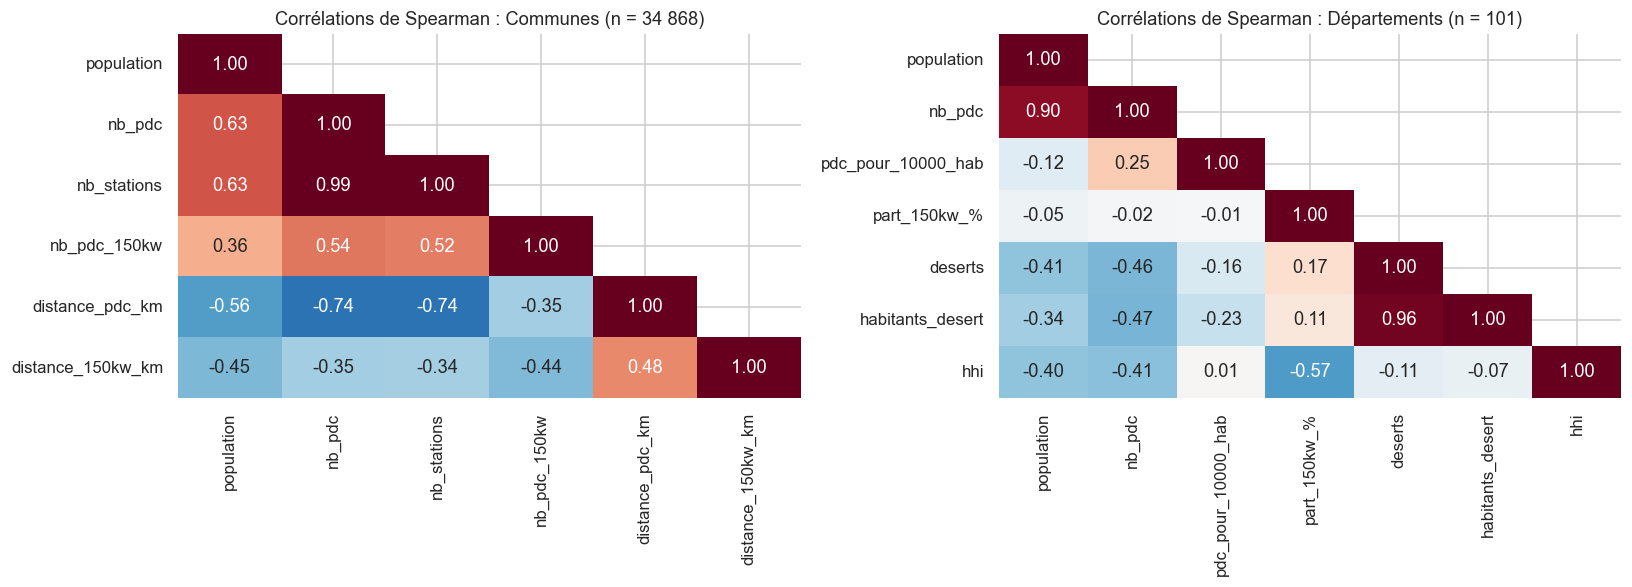

                    population  nb_pdc  pdc_pour_10000_hab  part_150kw_%  deserts  habitants_desert   hhi
population                1.00    0.90               -0.12         -0.05    -0.41             -0.34 -0.40
nb_pdc                    0.90    1.00                0.25         -0.02    -0.46             -0.47 -0.41
pdc_pour_10000_hab       -0.12    0.25                1.00         -0.01    -0.16             -0.23  0.01
part_150kw_%             -0.05   -0.02               -0.01          1.00     0.17              0.11 -0.57
deserts                  -0.41   -0.46               -0.16          0.17     1.00              0.96 -0.11
habitants_desert         -0.34   -0.47               -0.23          0.11     0.96              1.00 -0.07
hhi                      -0.40   -0.41                0.01         -0.57    -0.11             -0.07  1.00


In [13]:
variables_communes = ["population", "nb_pdc", "nb_stations", "nb_pdc_150kw", "distance_pdc_km",
                      "distance_150kw_km"]
correlation_communes = communes[variables_communes].corr(method="spearman")
variables_departements = ["population", "nb_pdc", "pdc_pour_10000_hab", "part_150kw_%", "deserts",
                          "habitants_desert", "hhi"]
correlation_departements = departements[variables_departements].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, matrice, titre in [(axes[0], correlation_communes, f"Communes (n = {len(communes):,})".replace(",", " ")),
                           (axes[1], correlation_departements, f"Départements (n = {len(departements)})")]:
  sns.heatmap(matrice, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar=False,
              mask=np.triu(np.ones_like(matrice, dtype=bool), k=1))
  ax.set_title(f"Corrélations de Spearman : {titre}")
plt.tight_layout()
plt.show()
print(correlation_departements.round(2).to_string())


**Lecture.**
- À l'échelle des départements, population et nombre de points sont très liés (0,90), mais l'équipement par habitant ne dépend pas de la taille du département (−0,12).
- Plus un département est concentré entre peu d'opérateurs, plus sa part de points de 150 kW et plus est faible (−0,57) : dans les départements les plus concentrés, l'acteur dominant exploite surtout des points de 22 kW ou moins (axe 3).
- Les départements les plus peuplés ont moins de communes en désert (−0,41).
- À l'échelle des communes, les distances au point le plus proche diminuent quand la population augmente (corrélations négatives) : les déserts sont des communes peu peuplées.

**Limite.** Ces corrélations décrivent des associations, pas des causes ; à l'échelle départementale, elles portent sur 101 observations seulement.

## Tendances du déploiement

Points datés : 101,228 sur 166,430 (60.8 %)
       mises_en_service  part_150kw
annee                              
2015                266        72.9
2016                950        34.0
2017               1394        21.7
2018                514        20.0
2019               1813        27.0
2020               2241        16.6
2021              10171         8.8
2022              13348        22.8
2023              19872        27.5
2024              19615        31.9
2025              21500        28.3
2026               9197        25.8

Part des points datés par région (%) : {'La Réunion': 0.0, 'Guadeloupe': 4.0, 'Martinique': 13.0, 'Corse': 32.0, 'Guyane': 33.0, 'Nouvelle-Aquitaine': 55.0, 'Bourgogne-Franche-Comté': 55.0, 'Grand Est': 59.0, 'Pays de la Loire': 60.0, 'Hauts-de-France': 60.0, 'Auvergne-Rhône-Alpes': 60.0, 'Île-de-France': 61.0, 'Bretagne': 62.0, 'Occitanie': 63.0, "Provence-Alpes-Côte d'Azur": 64.0, 'Centre-Val de Loire': 73.0, 'Normandie': 73.0}


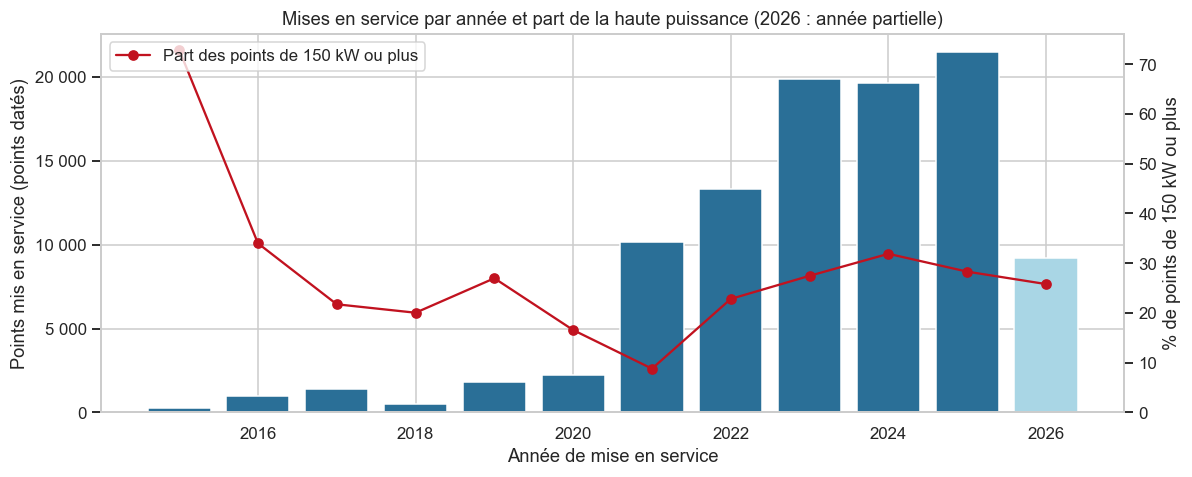

In [14]:
datees = points.dropna(subset=["date_mise_en_service"]).copy()
datees["annee"] = datees["date_mise_en_service"].dt.year
print(f"Points datés : {len(datees):,} sur {len(points):,} ({len(datees) / len(points) * 100:.1f} %)")
par_annee = datees.loc[datees["annee"].between(2015, 2026)].groupby("annee").agg(
    mises_en_service=("id_pdc", "size"), part_150kw=("puissance_kw", lambda s: (s >= 150).mean() * 100))
print(par_annee.round(1).to_string())
couverture = points.groupby("region")["date_mise_en_service"].apply(lambda s: s.notna().mean() * 100)
print("\nPart des points datés par région (%) :", couverture.round(0).sort_values().to_dict())

fig, ax1 = plt.subplots(figsize=(11, 4.5))
annees = par_annee.index.astype(int)
barres = ax1.bar(annees, par_annee["mises_en_service"], color=["#2a6f97"] * (len(annees) - 1) + ["#a9d6e5"])
ax1.set(xlabel="Année de mise en service", ylabel="Points mis en service (points datés)")
ax1.yaxis.set_major_formatter(milliers)
ax2 = ax1.twinx()
ax2.plot(annees, par_annee["part_150kw"], color="#c1121f", marker="o", label="Part des points de 150 kW ou plus")
ax2.set(ylabel="% de points de 150 kW ou plus", ylim=(0, None))
ax2.grid(False)
ax2.legend(loc="upper left")
ax1.set_title("Mises en service par année et part de la haute puissance (2026 : année partielle)")
plt.tight_layout()
plt.show()


**Lecture.**
- Les mises en service ont doublé entre 2021 (10 171 points datés) et 2025 (21 500). L'année 2026 est partielle (données arrêtées fin août : 9 197 points).
- La part des points de 150 kW et plus parmi les nouvelles installations est passée de 8,8 % en 2021 à 31,9 % en 2024, puis 28,3 % en 2025 : le déploiement s'oriente vers la recharge ultra-rapide.
- Les années 2015 à 2020 portent sur peu de points (266 à 2 241) : leurs pourcentages sont instables.

**Limite importante.** Seuls 60,8 % des points ont une date de mise en service, et l'absence de date dépend du producteur : 0 % de points datés à La Réunion, 4 % en Guadeloupe, 73 % en Normandie. Ces tendances décrivent les points datés, pas l'ensemble du parc ; elles indiquent une direction, pas un rythme exact.

## Synthèse

| Axe | Constat principal | Chiffre clé |
|---|---|---|
| Couverture | La couverture est large : la moitié de la population vit à moins de 640 m d'un point | 0,90 % de la population en désert de recharge (685 communes) |
| Déserts | Les déserts de métropole sont de petites communes rurales du nord-est ; en population, les déserts sont d'abord ultramarins | Mayotte : 0 point pour 256 518 habitants |
| Puissance | Le parc reste dominé par la recharge à 22 kW ; l'ultra-rapide progresse | 18,6 % de points de 150 kW et plus ; 31,9 % des mises en service de 2024 |
| Recharge ultra-rapide | Absente des Antilles et de la Guyane ; inégale en métropole | 1,66 million d'habitants en désert 150 kW (2,44 %) |
| Acteurs | Marché national fragmenté, mais monopoles locaux | 9 départements très concentrés (HHI > 2 500) |

**Indicateurs proposés pour le tableau de bord :**
- part de la population en désert de recharge et en désert 150 kW ;
- points de charge pour 10 000 habitants, par département (carte) ;
- part des points de 150 kW et plus, par région ;
- distance médiane au point le plus proche, pondérée par la population ;
- indice de concentration des opérateurs (HHI) par département ;
- évolution annuelle des mises en service (points datés).